# Exploratory Data Analysis of SEC Financial Statements

In this notebook, we analyse  financial statement data published by the U.S. Securities and Exchange Commission (SEC).

The analysis follows a step-by-step process: first understanding the data, then cleaning it, exploring patterns, answering research questions, and finally presenting meaningful findings.

## EDA Flow

| Part | What we do |
|---|---|
| 1 | Know the Data |
| 2 | Load and Understand the Data |
| 3 | Research Questions |
| 4 | Data Cleaning |
| 5 | Univariate Analysis |
| 6 | Bivariate Analysis |
| 7 | Answer Research Questions |
| 8 | Conclusion |

# Part 1: Know the Data

## Step 1: Data Card

| Attribute | Description |
|---|---|
| Dataset Name | SEC Financial Statements |
| Data Source | U.S. Securities and Exchange Commission (SEC) |
| Dataset File | SEC_Data.csv |
| Dataset Size | 100,000 rows × 17 columns |
| Data Coverage	| January 2023 – November 2025 |
| Data Category | Financial and company-related data |
| Observation | One financial fact reported in an SEC filing |
| Project Objective | To identify patterns, trends, and relationships in financial data |

**Dataset Source:** [SEC Financial Statement Data Sets](https://www.sec.gov/data-research/sec-markets-data/financial-statement-data-sets)

Each row represents a reported financial fact, such as revenue or assets, associated with a company and a reporting period.

## Step 2: Column Guide

| Column | Description |
|---|---|
| `adsh` | Unique identifier for an SEC filing |
| `tag` | Accounting concept being reported, such as revenue or assets |
| `version` | Taxonomy version used for the financial concept |
| `ddate` | Date associated with the reported financial fact |
| `qtrs` | Number of quarters covered by the reported value |
| `uom` | Unit of measure, such as USD or shares |
| `segments` | Segment information, if reported |
| `coreg` | Co-registrant name, if applicable |
| `value` | Reported financial value |
| `footnote` | Reference to additional filing notes |
| `cik` | SEC Central Index Key identifying the company |
| `name` | Company name |
| `form` | Filing type, such as 10-K or 10-Q |
| `period` | End date of the reporting period |
| `fy` | Fiscal year of the company |
| `fp` | Fiscal period, such as Q1, Q2, Q3, or FY |
| `filed` | Date the filing was submitted to the SEC |

The dataset contains financial facts reported by different companies, using different accounting concepts and units. Therefore, financial values must be interpreted alongside their tags and units.

# Part 2: Load and Understand the Data

#### Step 1: Import Libraries

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


#### Step 2: Load the Dataset

We load the prepared SEC financial dataset using Pandas.

In [3]:
df = pd.read_csv("../Dataset/SEC_Data.csv")

#### Step 3: Check Dataset Shape

We check the number of rows and columns in the dataset.

In [4]:
df.shape

(100000, 17)

The dataset contains 100,000 rows and 17 columns, providing information about financial facts and the companies that reported them.

#### Step 4: Preview the Dataset

We display the first and last five rows to examine the structure and contents of the dataset.

In [5]:
display("First Five Rows:")
display(df.head())

display("Last Five Rows:")
display(df.tail())

'First Five Rows:'

,adsh,tag,version,ddate,qtrs,uom,segments,coreg,value,footnote,cik,name,form,period,fy,fp,filed
0,0001628280-25-049910,OtherAssets,us-gaap/2025,20250930,0,USD,BusinessSegments=KuduInvestmentManagementLLCSe...,NaN,23100000.0,NaN,776867,WHITE MOUNTAINS INSURANCE GROUP LTD,10-Q,20250930,2025.0,Q3,20251106
1,0001037540-25-000013,NotesReceivableNet,us-gaap/2025,20250930,0,USD,FairValueByMeasurementBasis=CarryingReportedAm...,NaN,88879000.0,NaN,1037540,"BXP, INC.",10-Q,20250930,2025.0,Q3,20251107
2,0001628280-25-047886,LimitedPartnersCapitalAccount,us-gaap/2025,20250930,0,USD,ConsolidatedEntities=Subsidiaries;,NaN,280873000.0,NaN,1040971,SL GREEN REALTY CORP,10-Q,20250930,2025.0,Q3,20251103
3,0001493152-25-023588,AccrualOfSeriesIConvertiblePreferredStockDivid...,0001493152-25-023588,20250930,3,USD,NaN,NaN,53472.0,NaN,1086745,"STABLEX TECHNOLOGIES, INC.",10-Q,20250930,2025.0,Q3,20251114
4,0001437749-25-034698,InterestExpenseNonoperating,us-gaap/2025,20250930,3,USD,NaN,NaN,123723.0,NaN,1581552,"ENERGY 11, L.P.",10-Q,20250930,2025.0,Q3,20251113


'Last Five Rows:'

,adsh,tag,version,ddate,qtrs,uom,segments,coreg,value,footnote,cik,name,form,period,fy,fp,filed
99995,0001628280-25-055819,OperatingLeaseLiabilityCurrent,us-gaap/2025,20250131,0,USD,NaN,NaN,1.860400e+07,NaN,1614178,"YEXT, INC.",10-Q,20251031,2026.0,Q3,20251208
99996,0001767258-25-000068,ProfitLoss,us-gaap/2025,20250930,1,USD,EquityComponents=RetainedEarnings;,NaN,1.294000e+07,NaN,1767258,"XPEL, INC.",10-Q,20250930,2025.0,Q3,20251107
99997,0001109357-25-000182,TrueUpAdjustmentsToDecouplingMechanismsAndForm...,0001109357-25-000182,20250930,1,USD,LegalEntity=PepcoHoldingsLLC;,PepcoHoldingsLLC,6.000000e+06,NaN,1109357,EXELON CORP,10-Q,20250930,2025.0,Q3,20251104
99998,0000907471-25-000116,LaborAndRelatedExpense,us-gaap/2025,20230930,4,USD,NaN,NaN,1.843180e+08,NaN,907471,"PATHWARD FINANCIAL, INC.",10-K,20250930,2025.0,FY,20251125
99999,0001193125-25-269512,InvestmentOwnedAtFairValue,us-gaap/2025,20250930,0,USD,ScheduleOfEquityMethodInvestmentEquityMethodIn...,NaN,2.775216e+09,NaN,1278752,MIDCAP FINANCIAL INVESTMENT CORP,10-Q,20250930,2025.0,Q3,20251106


#### Step 5 — Dataset Information
We'll check column names, data types, and non-null counts together using:

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   adsh      100000 non-null  str    
 1   tag       100000 non-null  str    
 2   version   100000 non-null  str    
 3   ddate     100000 non-null  int64  
 4   qtrs      100000 non-null  int64  
 5   uom       100000 non-null  str    
 6   segments  59217 non-null   str    
 7   coreg     1061 non-null    str    
 8   value     96430 non-null   float64
 9   footnote  249 non-null     str    
 10  cik       100000 non-null  int64  
 11  name      100000 non-null  str    
 12  form      100000 non-null  str    
 13  period    100000 non-null  int64  
 14  fy        100000 non-null  float64
 15  fp        100000 non-null  str    
 16  filed     100000 non-null  int64  
dtypes: float64(2), int64(5), str(10)
memory usage: 13.0 MB


The dataset contains 100,000 records and 17 columns with different data types. Several columns contain missing values, while date-related columns are currently stored as integers.

#### Step 6: Summary Statistics

We examine the statistical summary of numerical columns to understand their distributions and ranges.

In [7]:
df.describe()

,ddate,qtrs,value,cik,period,fy,filed
count,1.000000e+05,100000.00000,9.643000e+04,1.000000e+05,1.000000e+05,100000.00000,1.000000e+05
mean,2.024558e+07,1.11479,9.844382e+08,1.354000e+06,2.025087e+07,2025.05937,2.025110e+07
std,3.256066e+04,1.31345,3.232599e+10,5.503673e+05,8.156339e+02,0.26307,4.246141e+01
min,1.011123e+07,0.00000,-1.327430e+11,1.800000e+03,2.023013e+07,2023.00000,2.025100e+07
25%,2.024093e+07,0.00000,5.000000e-02,1.023994e+06,2.025093e+07,2025.00000,2.025110e+07
50%,2.025033e+07,1.00000,1.573408e+06,1.498547e+06,2.025093e+07,2025.00000,2.025111e+07
75%,2.025093e+07,3.00000,3.718795e+07,1.803914e+06,2.025093e+07,2025.00000,2.025111e+07
max,2.029093e+07,41.00000,4.076945e+12,2.081125e+06,2.025113e+07,2027.00000,2.025123e+07


- The `value` column has 96,430 non-null values.
- Financial values vary widely, from -132.7 billion to 4.08 trillion.
- The mean is much higher than the median, indicating an uneven distribution.
- The `qtrs` column ranges from 0 to 41, requiring further investigation.

These results highlight variations and unusual values for further analysis.

#### Step 7: Examine Categorical Columns

We examine the frequency of categorical values to understand filing types, fiscal periods, and units of measurement.

In [8]:
print("Filing Types:")
display(df['form'].value_counts())

print("Fiscal Periods:")
display(df['fp'].value_counts())

print("Units of Measurement:")
display(df['uom'].value_counts())

Filing Types:


form
10-Q    93235
10-K     6765
Name: count, dtype: int64

Fiscal Periods:


fp
Q3    86305
FY     6763
Q2     3923
Q1     3009
Name: count, dtype: int64

Units of Measurement:


uom
USD          85347
pure          7354
shares        6941
CAD            111
Rate           102
EUR             65
GBP             37
Contract         8
AUD              8
SEK              4
CHF              3
contract         3
oz               3
CNY              3
NOK              2
TWD              2
JPY              2
Ethereum         1
Contracts        1
DKK              1
NZD              1
ARS              1
Name: count, dtype: int64

### Interpretation

- **Filing Types:** Most records belong to 10-Q filings (93,235).
- **Fiscal Periods:** Q3 is the most frequent reporting period (86,305).
- **Units:** USD is the most common unit of measurement (85,347).

The dataset is mainly composed of quarterly filings, particularly Q3, with financial values mostly reported in USD.

#### Step 8: Explore Accounting Concepts

We identify the most frequently reported accounting concepts in the dataset.

In [9]:
df["tag"].value_counts().head(10)

tag
InvestmentOwnedAtFairValue                                                4150
StockholdersEquity                                                        4065
InvestmentOwnedAtCost                                                     3332
RevenueFromContractWithCustomerExcludingAssessedTax                       3163
StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest    2404
InvestmentOwnedBalancePrincipalAmount                                     2393
NetIncomeLoss                                                             2126
InvestmentBasisSpreadVariableRate                                         2033
InvestmentOwnedPercentOfNetAssets                                         2021
InvestmentInterestRate                                                    1855
Name: count, dtype: int64

### Interpretation

- Investment-related concepts appear frequently in the dataset.
- Stockholders' Equity is another commonly reported concept.
- Revenue and Net Income are also among the top 10 accounting concepts.

This indicates that the dataset covers various financial areas, including investments, equity, revenue, and profitability.

#### Step 9: Explore Company Distribution

We identify the companies contributing the most financial records to the dataset.

In [10]:
df["name"].value_counts().head(10)

name
BLACKSTONE PRIVATE CREDIT FUND         701
GOLUB CAPITAL BDC, INC.                574
ARES CAPITAL CORP                      556
ARES STRATEGIC INCOME FUND             435
STEPSTONE PRIVATE CREDIT FUND LLC      399
ANTARES STRATEGIC CREDIT FUND          357
MONROE CAPITAL INCOME PLUS CORP        346
GOLUB CAPITAL DIRECT LENDING CORP      344
NORTH HAVEN PRIVATE INCOME FUND LLC    327
ANTARES PRIVATE CREDIT FUND            316
Name: count, dtype: int64

### Interpretation

- BLACKSTONE PRIVATE CREDIT FUND has the highest number of records (701).
- Most companies in the top 10 are private credit or investment funds.
- The number of records varies across companies.

This shows that financial records are not evenly distributed among companies.

#### Step 10: Explore Reporting Periods

We examine the reporting periods to understand the time coverage of the dataset.

In [11]:
print("Reporting Periods:")
display(df["period"].value_counts().sort_index())

print("Financial Periods:")
display(df["ddate"].value_counts().sort_index().head(10))

Reporting Periods:


period
20230131        2
20230331        8
20230430        4
20230630        9
20230930       23
20231231       19
20240331       40
20240630       55
20240930       81
20241031        2
20241231      231
20250331      306
20250430       69
20250531        8
20250630      845
20250731      298
20250831     1464
20250930    93269
20251031     3008
20251130      259
Name: count, dtype: int64

Financial Periods:


ddate
10111231    1
19971031    1
20100531    1
20110228    1
20111031    1
20140531    1
20160930    2
20170430    1
20170930    1
20180131    1
Name: count, dtype: int64

### Interpretation

- Most records belong to the September 2025 reporting period (93,269).
- The dataset contains reporting periods from January 2023 to November 2025.
- Financial fact dates (`ddate`) extend beyond the reporting periods shown, requiring further investigation.

The dataset is heavily concentrated in Q3 2025, which may affect our analysis.

#### Step 11: Check Unique Values

We count unique values in selected columns to understand the variety of records.

In [59]:
print("Unique Companies:", df["cik"].nunique())
print("Unique Filing Types:", df["form"].nunique())
print("Unique Accounting Concepts:", df["tag"].nunique())
print("Unique Filing IDs:", df["adsh"].nunique())

Unique Companies: 5453
Unique Filing Types: 2
Unique Accounting Concepts: 8466
Unique Filing IDs: 5615


### Interpretation

- The dataset contains **5,453 unique companies**.
- It includes **2 filing types**: 10-K and 10-Q.
- There are **8,466 unique accounting concepts**.
- The records belong to **5,615 unique SEC filings**.

This shows considerable diversity in companies, filings, and reported financial concepts.

#### Step 12: Check Duplicate Records

We check for duplicate rows to identify repeated records in the dataset.

In [13]:
df.duplicated().sum()

np.int64(0)

### Interpretation

The dataset contains no exact duplicate rows. Therefore, no duplicate records need to be removed.

# Part 3: Research Questions

The following questions will guide our exploratory data analysis:

| No. | Research Question |
|---|---|
| Q1 | How are financial values distributed across the dataset? |
| Q2 | How does the number of reported quarters vary across records? |
| Q3 | Which accounting concepts appear most frequently? |
| Q4 | Which companies have the highest number of financial records? |
| Q5 | How are records distributed between 10-K and 10-Q filings? |
| Q6 | How do financial records vary across reporting periods? |
| Q7 | How does the distribution of `qtrs` differ between 10-K and 10-Q filings? |
| Q8 | Which accounting concepts have the highest number of missing financial values? |

These questions cover univariate analysis, bivariate analysis, and group comparisons.

# Part 4: Data Cleaning

In this section, we identify and handle missing values, duplicate records, incorrect data types, and potential outliers to prepare the dataset for analysis.

#### Step 13: Check Missing Values

We identify missing values in each column to understand data completeness.

In [14]:
df.isnull().sum()

adsh            0
tag             0
version         0
ddate           0
qtrs            0
uom             0
segments    40783
coreg       98939
value        3570
footnote    99751
cik             0
name            0
form            0
period          0
fy              0
fp              0
filed           0
dtype: int64

### Interpretation: 
- `segments`, `coreg`, and `footnote` contain missing values because these fields are not always applicable.
- The `value` column has 3,570 missing entries.
- Other columns contain no missing values.

Optional fields will be retained, while missing financial values will be investigated separately.

#### Step 14: Examine Missing Financial Values

We inspect records with missing financial values to understand their characteristics.

In [58]:
df.loc[df["value"].isnull()].head()

,adsh,tag,version,ddate,qtrs,uom,segments,coreg,value,footnote,cik,name,form,period,fy,fp,filed,value_missing
14,0001493152-25-022425,OtherComprehensiveIncomeForeignCurrencyTransac...,us-gaap/2025,2025-06-30,1,USD,EquityComponents=AdditionalPaidInCapital;,NaN,NaN,NaN,1879001,VERSES AI INC.,10-Q,2025-09-30,2026.0,Q2,2025-11-14,True
25,0001842563-25-000022,NetIncomeLoss,us-gaap/2024,2025-03-31,1,USD,EquityComponents=AdditionalPaidInCapital;,NaN,NaN,NaN,1842563,"GO GO BUYERS, INC.",10-Q,2025-09-30,2025.0,Q3,2025-11-07,True
141,0001829126-25-009213,NetIncomeLossAvailableToCommonStockholdersBasic,us-gaap/2024,2025-03-31,1,USD,EquityComponents=AdditionalPaidInCapital;,NaN,NaN,NaN,1860514,ROTH CH ACQUISITION CO.,10-Q,2025-09-30,2025.0,Q3,2025-11-14,True
149,0001213900-25-105077,NetIncomeLoss,us-gaap/2025,2025-06-30,1,USD,Geographical=Europe;OperatingActivitiesSegment...,NaN,NaN,NaN,1883984,"ALTERNUS CLEAN ENERGY, INC.",10-Q,2025-06-30,2025.0,Q2,2025-11-03,True
168,0001213900-25-112611,StockIssuedDuringPeriodValueReclassificationOf...,0001213900-25-112611,2025-03-31,1,USD,EquityComponents=RetainedEarnings;ErrorCorrect...,NaN,NaN,NaN,1874097,CYNGN INC.,10-Q,2025-09-30,2025.0,Q3,2025-11-19,True


### Interpretation

The selected records contain missing (`NaN`) values in the `value` column. These entries represent unavailable financial amounts and require further investigation before removal.

#### Step 15: Identify Accounting Concepts with Missing Values

We examine which accounting concepts have missing financial values to identify any patterns.

In [16]:
df[df["value"].isnull()]["tag"].value_counts().head()

tag
NetIncomeLoss                                                                                       324
CommitmentsAndContingencies                                                                         200
StockholdersEquity                                                                                  124
AdjustmentsToAdditionalPaidInCapitalSharebasedCompensationRequisiteServicePeriodRecognitionValue    110
ProfitLoss                                                                                          108
Name: count, dtype: int64

### Interpretation

- `NetIncomeLoss` has the highest number of missing values (324).
- Missing values also occur in `CommitmentsAndContingencies` and `StockholdersEquity`.
- Missing values are concentrated in certain accounting concepts.

This suggests that missing financial values are not evenly distributed across accounting concepts. Their cause requires further investigation.

#### Step 16: Examine Missing Values by Filing Type

We compare missing financial values in 10-Q and 10-K filings to identify whether missing values are more common in a particular filing type.

In [17]:
df[df["value"].isnull()]["form"].value_counts()

form
10-Q    3402
10-K     168
Name: count, dtype: int64

### Interpretation

- Most missing financial values occur in 10-Q filings (3,402).
- 10-K filings contain 168 missing values.
- Since the dataset contains more 10-Q filings, these counts alone cannot determine which filing type has a higher missing-value rate.

Further comparison using percentages is needed.

#### Step 17: Compare Missing Value Rates

We calculate the percentage of missing financial values in each filing type to make a fair comparison between 10-Q and 10-K filings.

In [18]:
df.groupby("form")["value"].apply(
    lambda x: x.isnull().mean() * 100
)

form
10-K    2.483370
10-Q    3.648844
Name: value, dtype: float64

### Interpretation

- 10-Q filings have a missing-value rate of approximately 3.65%.
- 10-K filings have a missing-value rate of approximately 2.48%.
- Missing financial values are proportionally more common in 10-Q filings.

This comparison shows that missing values occur at a higher rate in quarterly filings than in annual filings.

#### Step 18: Calculate Overall Missing Value Percentage

We calculate the percentage of missing financial values to understand how much of the dataset is affected.

In [19]:
missing_value_percent= df["value"].isnull().mean() * 100

print("Missing Value Percentage:", missing_value_percent)

Missing Value Percentage: 3.5700000000000003


Approximately 3.57% of the dataset's financial values are missing, while 96.43% are available.

We will retain records with missing financial values rather than replacing them with estimates. These records will be excluded only from analyses that require numerical financial values.

#### Step 19: Handle Missing Financial Values

Missing financial values will be retained because removing these rows would also discard useful company and filing information. They will be excluded only from analyses that require actual numerical values.

In [20]:
df["value"].isnull().sum()

np.int64(3570)

### Interpretation

A total of 3,570 missing values remain in the `value` column. These records are retained to preserve other useful information, such as company names, accounting concepts, and filing details.

Missing values will be excluded only when required for specific numerical analyses.

#### Step 20: Identify Missing Value Patterns

We investigate whether missing financial values are concentrated among specific companies or accounting concepts before proceeding with numerical analysis.

In [21]:
df["value_missing"] = df["value"].isnull()

In [22]:
df.groupby('name')["value_missing"].mean().sort_values(ascending=False).head(10) * 100

name
AG ACQUISITION GROUP III, INC.            100.000000
CANARY HBAR ETF                           100.000000
INFLECTION POINT ACQUISITION CORP. III     80.000000
UBUYHOLDINGS INC                           80.000000
FERMI INC.                                 77.777778
FINTRADE SHERPA, INC.                      75.000000
SKYX PLATFORMS CORP.                       75.000000
THARIMMUNE, INC.                           66.666667
FACT II ACQUISITION CORP.                  66.666667
FUTURE VISION II ACQUISITION CORP.         66.666667
Name: value_missing, dtype: float64

### Interpretation

- Some companies have a high percentage of missing financial values.
- AG ACQUISITION GROUP III, INC. and CANARY HBAR ETF have 100% missing-value rates in the sample.
- Missing values may be concentrated among specific companies.

Further investigation of company record counts is required before drawing conclusions.

In [64]:
missing_by_company= df.groupby("name")["value_missing"].agg(
    missing_count="sum",
    total_records="count",
    missing_rate="mean"
)

missing_by_company["missing_rate"] *= 100

display(
    missing_by_company.sort_values(
        'missing_rate', ascending=False
    ).head(10)
)


,missing_count,total_records,missing_rate
name,,,
"AG ACQUISITION GROUP III, INC.",2,2,100.000000
CANARY HBAR ETF,1,1,100.000000
INFLECTION POINT ACQUISITION CORP. III,4,5,80.000000
UBUYHOLDINGS INC,4,5,80.000000
FERMI INC.,7,9,77.777778
"FINTRADE SHERPA, INC.",3,4,75.000000
SKYX PLATFORMS CORP.,3,4,75.000000
"THARIMMUNE, INC.",6,9,66.666667
FACT II ACQUISITION CORP.,4,6,66.666667


### Interpretation

- All 10 companies have more missing than available financial values.
- Some companies have very few records, making their missing rates less representative.
- Canary HBAR ETF has only one record, and its value is missing.
- Fermi Inc. has 7 missing values out of 9 records.

These results suggest that missing financial values may be concentrated among certain companies. However, the small number of records limits our conclusions.

#### Step 21: Examine Missing Values by Accounting Concept

We compare missing financial values across accounting concepts to identify which concepts have higher missing-value rates.

In [24]:
missing_by_tag= df.groupby("tag")["value_missing"].agg(
    missing_count="sum",
    total_records="count",
    missing_rate="mean"
)

missing_by_tag['missing_rate'] *= 100

display(
    missing_by_tag.sort_values(
        'missing_rate', ascending=False
    ).head(10)
)


,missing_count,total_records,missing_rate
tag,,,
LossOnConversion,1,1,100.0
tockIssuedDuringPeriodValueGrantAndImmediateExerciseOfWarrants,1,1,100.0
StockIssuedDuringPeriodValueConversionOfCommonStockClassDToCommonStock,1,1,100.0
StockIssuedDuringPeriodValueConversionOfClassASubordinateVotingSharesIntoClassBProportionateVotingShares,2,2,100.0
StockIssuedDuringPeriodValueConversionOfAccountsPayableToCommonStock,1,1,100.0
AllocatedValueOfTransactionCostsToRightsIncludedInPublicUnits,1,1,100.0
CashPaidForTheSettlementOfTheStockBasedCompensationLiability,1,1,100.0
DeemedDividendForDownRoundOfShares,1,1,100.0
IssuanceOfRegaWarrants,1,1,100.0


### Interpretation

- The top 10 accounting concepts have a 100% missing-value rate.
- Most of these concepts appear only once in the dataset.
- Their small record counts make the missing rates less representative.

This suggests that missing financial values occur in some less frequently reported accounting concepts. However, further investigation is needed before drawing conclusions.

#### Step 22: Examine Missing Values by Reporting Period

We compare missing financial values across reporting periods to identify whether missing values are concentrated in specific periods.

In [25]:
missing_by_period = df.groupby('period')['value_missing'].agg(
    missing_count='sum',
    total_records='count',
    missing_rate='mean'
)

missing_by_period['missing_rate'] *= 100

display(missing_by_period.sort_index())

,missing_count,total_records,missing_rate
period,,,
20230131,0,2,0.000000
20230331,2,8,25.000000
20230430,0,4,0.000000
20230630,2,9,22.222222
20230930,1,23,4.347826
20231231,2,19,10.526316
20240331,5,40,12.500000
20240630,4,55,7.272727
20240930,8,81,9.876543


### Interpretation

- Missing-value rates vary across reporting periods.
- March 2023 has the highest missing rate (25%), but only 8 records.
- September 2025 contains the highest number of missing values (3,210), while its missing rate is 3.44%.
- The dataset is heavily concentrated in September 2025, which affects the missing-value counts.

Missing-value rates should be considered alongside the number of records in each reporting period.

#### Step 23: Visualise Missing Values by Reporting Period

We use a bar chart to show the number of missing financial values in each reporting period and identify periods with more missing records.

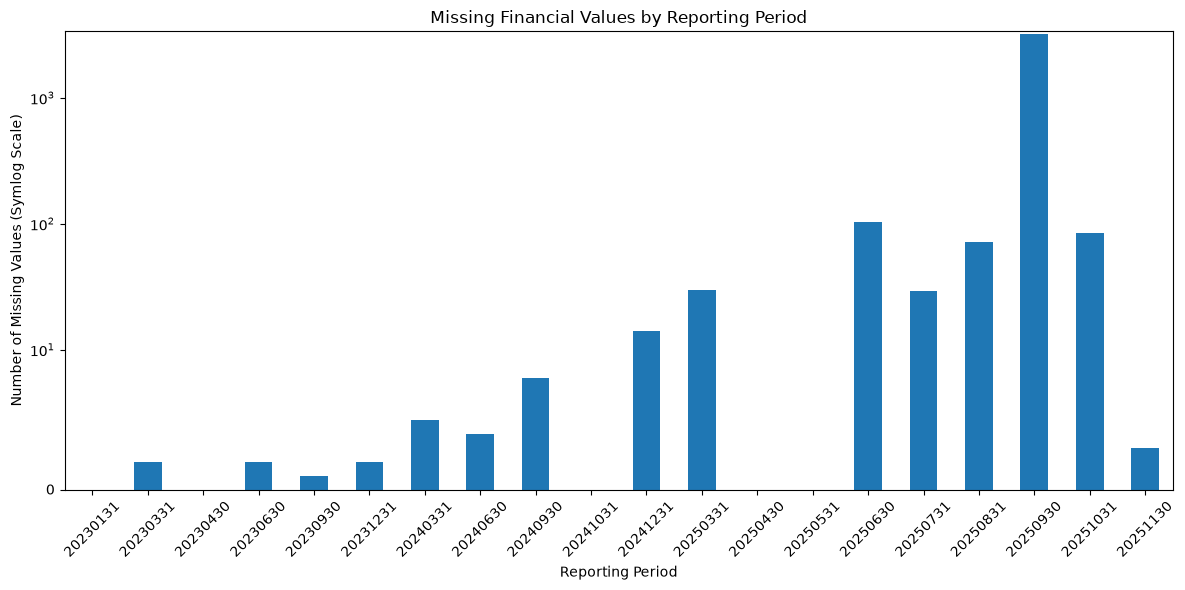

In [26]:
plt.figure(figsize=(12, 6))

missing_by_period['missing_count'].plot(kind='bar')

plt.yscale('symlog', linthresh=10)

plt.title('Missing Financial Values by Reporting Period')
plt.xlabel('Reporting Period')
plt.ylabel('Number of Missing Values (Symlog Scale)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation

- September 2025 has the highest number of missing financial values (3,210).
- October 2025 has 85 missing values, while August 2025 has 71.
- Several earlier reporting periods have very few or no missing values.
- The chart uses a symlog scale to make smaller counts visible alongside the much larger September 2025 count.

**Overall:** Missing financial values are concentrated heavily in September 2025, mainly because this reporting period contains the largest share of records in our dataset.

#### Step 25: Handle Missing Financial Values

The `value` column contains 3,570 missing values (3.57%).

We will keep these records because replacing missing financial amounts with mean or median could create misleading financial data. Missing values will be excluded only from analyses that require numerical values.

In [27]:
# Keep only records with available financial values
df_valid = df[df['value'].notna()]

print("Records for financial analysis:", len(df_valid))

Records for financial analysis: 96430


#### Step 26: Check Data Types

We check the data types of our columns to identify values that may need conversion before analysis.

In [28]:
df.dtypes

adsh                 str
tag                  str
version              str
ddate              int64
qtrs               int64
uom                  str
segments             str
coreg                str
value            float64
footnote             str
cik                int64
name                 str
form                 str
period             int64
fy               float64
fp                   str
filed              int64
value_missing       bool
dtype: object

#### Step 27: Convert Date Columns

The `ddate`, `period`, and `filed` columns contain dates stored as integers. We convert them into datetime format to make date-based analysis easier.

In [29]:
df = pd.read_csv("../Dataset/SEC_Data.csv")

In [30]:
date_columns = ['ddate', 'period', 'filed']

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column].astype(str),
        format='%Y%m%d',
        errors='coerce'
    )

#### Step 28: Verify Date Conversion

In [31]:
df[date_columns].dtypes

ddate     datetime64[us]
period    datetime64[us]
filed     datetime64[us]
dtype: object

#### Step 29: Check for Missing Dates

In [32]:
df[date_columns].isna().sum()

ddate     0
period    0
filed     0
dtype: int64

### Interpretation

- All three date columns have 0 missing values.
- All 100,000 records contain valid dates.
- Date conversion was successful, and no records were affected by invalid dates.

#### Step 30: Check Remaining Data Types

In [33]:
df.dtypes

adsh                   str
tag                    str
version                str
ddate       datetime64[us]
qtrs                 int64
uom                    str
segments               str
coreg                  str
value              float64
footnote               str
cik                  int64
name                   str
form                   str
period      datetime64[us]
fy                 float64
fp                     str
filed       datetime64[us]
dtype: object

The remaining columns have appropriate data types for analysis. No further data type conversions are required.

#### Step 31: Separate Numerical and Categorical Columns

We separate numerical and categorical columns into two groups to make further analysis easier and more organized.

In [34]:
numerical_cols = df.select_dtypes(include='number').columns.tolist()

categorical_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

In [35]:
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['qtrs', 'value', 'cik', 'fy']
Categorical Columns: ['adsh', 'tag', 'version', 'uom', 'segments', 'coreg', 'footnote', 'name', 'form', 'fp']


### Interpretation

- The dataset contains **4 numerical columns** and **10 categorical columns**.
- `qtrs`, `value`, and `fy` contain numerical information.
- `cik` is a numerical company identification number, not a measurement.
- Categorical columns contain company, filing, and accounting information.
- Date columns are stored separately in datetime format.

#### Step 32: Select Columns for Outlier Analysis

We exclude `cik` because it is a company identification number, not a measurable variable. We focus on numerical columns that may contain meaningful outliers.

In [36]:
outlier_cols = ['qtrs', 'value', 'fy']

#### Step 33: Examine Numerical Distributions

In [60]:
print(outlier_cols)
df.loc[:, outlier_cols].describe()

['qtrs', 'value', 'fy']


,qtrs,value,fy
count,100000.00000,9.643000e+04,100000.00000
mean,1.11479,9.844382e+08,2025.05937
std,1.31345,3.232599e+10,0.26307
min,0.00000,-1.327430e+11,2023.00000
25%,0.00000,5.000000e-02,2025.00000
50%,1.00000,1.573408e+06,2025.00000
75%,3.00000,3.718795e+07,2025.00000
max,41.00000,4.076945e+12,2027.00000


### Interpretation

- `qtrs` ranges from 0 to 41, with most values between 0 and 3.
- `value` contains both negative and positive financial amounts with a very wide range.
- `fy` ranges from 2023 to 2027, with most records belonging to 2025.
- The large standard deviation of `value` indicates considerable variation in financial amounts.

These statistics suggest potential outliers that require further investigation.

#### Step 34: Visualise Outliers Using Box Plots

We use box plots to visually identify potential outliers in our numerical columns. We begin with the `value` column to examine the distribution of financial amounts.

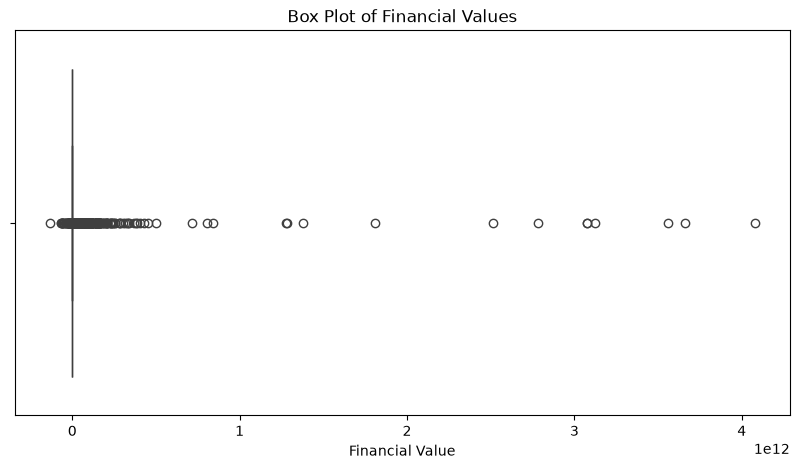

In [39]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['value'])
plt.title('Box Plot of Financial Values')
plt.xlabel('Financial Value')
plt.show()

### Interpretation

- The box plot shows a highly right-skewed distribution of financial values.
- Numerous potential outliers appear beyond the upper whisker.
- A few extremely large financial values stretch the distribution towards the right.
- These values may represent legitimate financial amounts rather than errors and require further investigation.

#### Step 35: Visualise Outliers in Quarters

We use a box plot to identify potential outliers in the `qtrs` column and examine the distribution of reported quarters.

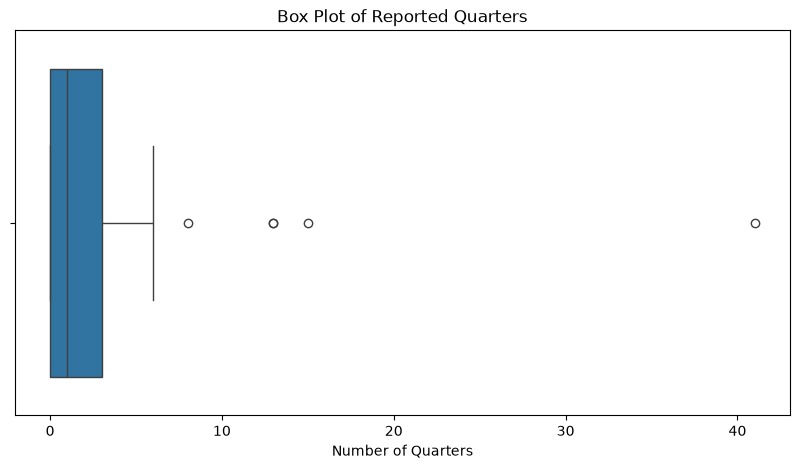

In [65]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['qtrs'])
plt.title('Box Plot of Reported Quarters')
plt.xlabel('Number of Quarters')
plt.show()

### Interpretation

- Most `qtrs` values are concentrated between 0 and 3.
- The median is approximately 1 quarter.
- The upper whisker extends to approximately 7 quarters.
- Several potential outliers appear beyond the upper whisker, including values as high as 41.
- These unusual values require further investigation before deciding whether they should be retained or removed.

#### Step 36: Calculate IQR for Quarters

We use the IQR method to calculate the lower and upper boundaries for identifying potential outliers in the `qtrs` column.

In [41]:
Q1 = df['qtrs'].quantile(0.25)
Q3 = df['qtrs'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 0.0
Q3: 3.0
IQR: 3.0
Lower Limit: -4.5
Upper Limit: 7.5


### Interpretation

- Q1 = 0 and Q3 = 3.
- The IQR is 3.
- The lower limit is -4.5 and the upper limit is 7.5.
- Values below -4.5 or above 7.5 are identified as potential outliers.
- Since `qtrs` cannot be negative, values above 7.5 are potential outliers.

#### Step 37: Count Potential Outliers

In [42]:
outliers_qtrs = df[df['qtrs'] > upper_limit]

print("Potential outliers:", len(outliers_qtrs))

Potential outliers: 5


### Interpretation

- Only **5 records** exceed the upper limit of 7.5.
- These records are potential outliers because they cover an unusually high number of quarters.
- We will inspect these values before deciding whether to remove them.

#### Step 38: Inspect Potential Outliers

In [43]:
outliers_qtrs[['tag', 'qtrs', 'value', 'uom', 'name']]

,tag,qtrs,value,uom,name
11981,StockRedeemedOrCalledDuringPeriodShares,13,4799446.0,shares,CREATIVE MEDIA & COMMUNITY TRUST CORP
16560,ProceedsFromIssuanceOfPreferredStockAndPrefere...,8,335100000.0,USD,"NEXPOINT REAL ESTATE FINANCE, INC."
42400,StockRepurchasedAndRetiredDuringPeriodValue,41,84800000.0,USD,"ORCHID ISLAND CAPITAL, INC."
55414,ProceedsFromSaleOfPropertyPlantAndEquipment,13,357000000.0,USD,NORFOLK SOUTHERN CORP
84013,ResearchAndDevelopmentExpense,15,5200000.0,USD,"LEXEO THERAPEUTICS, INC."


The five potential outliers contain unusually high quarter values, ranging from 8 to 41. Since these records may represent unusual reporting contexts, they will be retained rather than removed without further verification.

#### Step 39: Calculate IQR for Financial Values

We use the IQR method to identify unusually high or low financial values.

In [44]:
Q1_value = df['value'].quantile(0.25)
Q3_value = df['value'].quantile(0.75)

IQR_value = Q3_value - Q1_value

lower_limit_value = Q1_value - 1.5 * IQR_value
upper_limit_value = Q3_value + 1.5 * IQR_value

print("Q1:", Q1_value)
print("Q3:", Q3_value)
print("IQR:", IQR_value)
print("Lower Limit:", lower_limit_value)
print("Upper Limit:", upper_limit_value)

Q1: 0.05
Q3: 37187952.0
IQR: 37187951.95
Lower Limit: -55781927.87500001
Upper Limit: 92969879.92500001


### Interpretation

- Q1 = 0.05 and Q3 = 37,187,952.
- The IQR is 37,187,951.95.
- The lower limit is approximately -55,781,927.88.
- The upper limit is approximately 92,969,879.93.
- Values outside these limits are identified as potential outliers.

#### Step 40: Count Potential Outliers

In [45]:
outliers_value = df[
    (df['value'] < lower_limit_value) |
    (df['value'] > upper_limit_value)
]

print("Potential outliers:", len(outliers_value))

Potential outliers: 20288


### Interpretation

- **20,288 records** are identified as potential outliers.
- These values fall below the lower limit or above the upper limit.
- Financial values have a highly skewed distribution.
- Since the dataset contains different financial concepts and units, extreme values may be legitimate.
- Therefore, we will retain these records rather than remove them automatically.

#### Step 41: Handle Outliers

Potential outliers were identified in both `qtrs` and `value`.

We will retain these records because unusual financial values and reporting durations may be valid. Removing them without verification could result in the loss of important financial information.

# Part 5: Univariate Analysis

### Step 42: Distribution of Financial Values
#### Q1: How are financial values distributed across the dataset?

We use a histogram to examine the distribution of financial values and understand how frequently different value ranges occur.

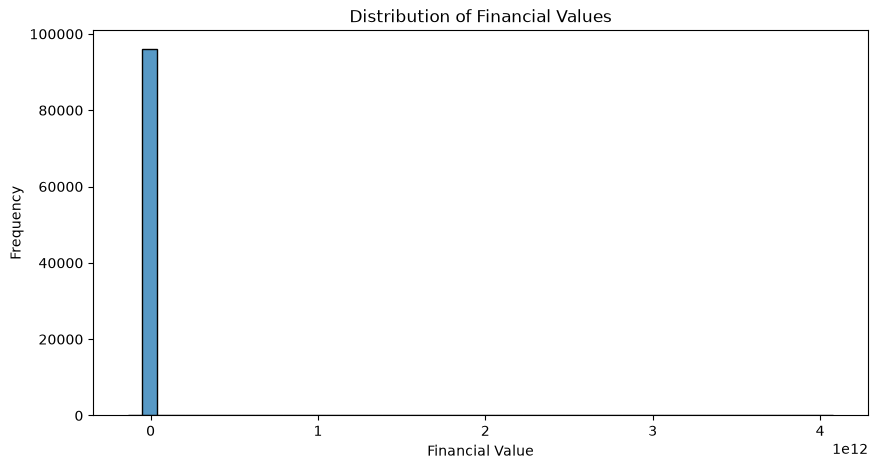

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='value', bins=50)

plt.title('Distribution of Financial Values')
plt.xlabel('Financial Value')
plt.ylabel('Frequency')

plt.show()

### Interpretation

- Most financial values are concentrated near zero.
- A small number of extremely large values stretch the x-axis.
- The distribution is highly right-skewed.
- The histogram appears compressed because of the large difference between smaller and larger financial values.

This distribution is not necessarily an error; it reflects the wide range of financial amounts in the dataset.

Since financial values represent different accounting concepts and units, their overall distribution should be interpreted with caution.

### Step 43: Distribution of Number of Quarters
#### Q2: How does the number of reported quarters vary across records?

This histogram examines how frequently different quarter durations appear in the dataset.

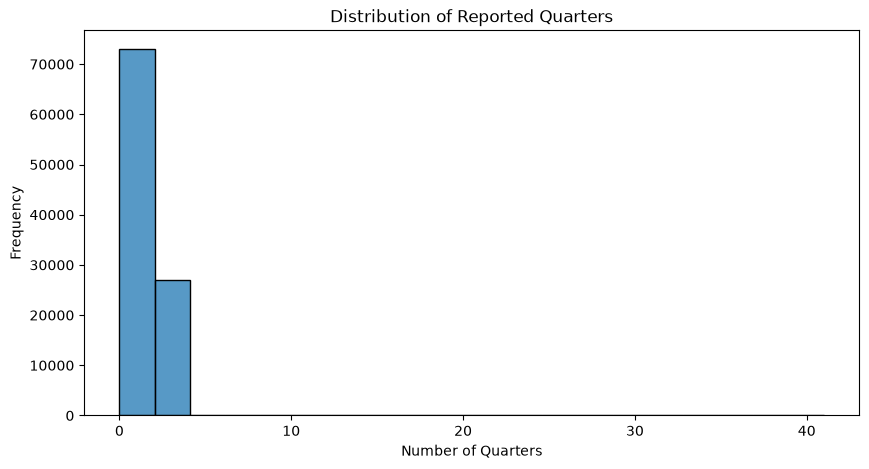

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='qtrs', bins=20)

plt.title('Distribution of Reported Quarters')
plt.xlabel('Number of Quarters')
plt.ylabel('Frequency')

plt.show()

### Interpretation

- Most records have `qtrs` values between 0 and 4.
- The frequency decreases significantly as the number of quarters increases.
- Only a small number of records have unusually high `qtrs` values, extending up to 41.
- These unusual values were also identified in our earlier box plot and IQR analysis.

**Overall:** Most financial facts in the dataset cover relatively short reporting durations, while a few records cover much longer periods.

### Step 44: Most Frequently Reported Accounting Concepts
#### Q3: Which accounting concepts appear most frequently?

We'll visualize the 10 most frequently reported accounting concepts.

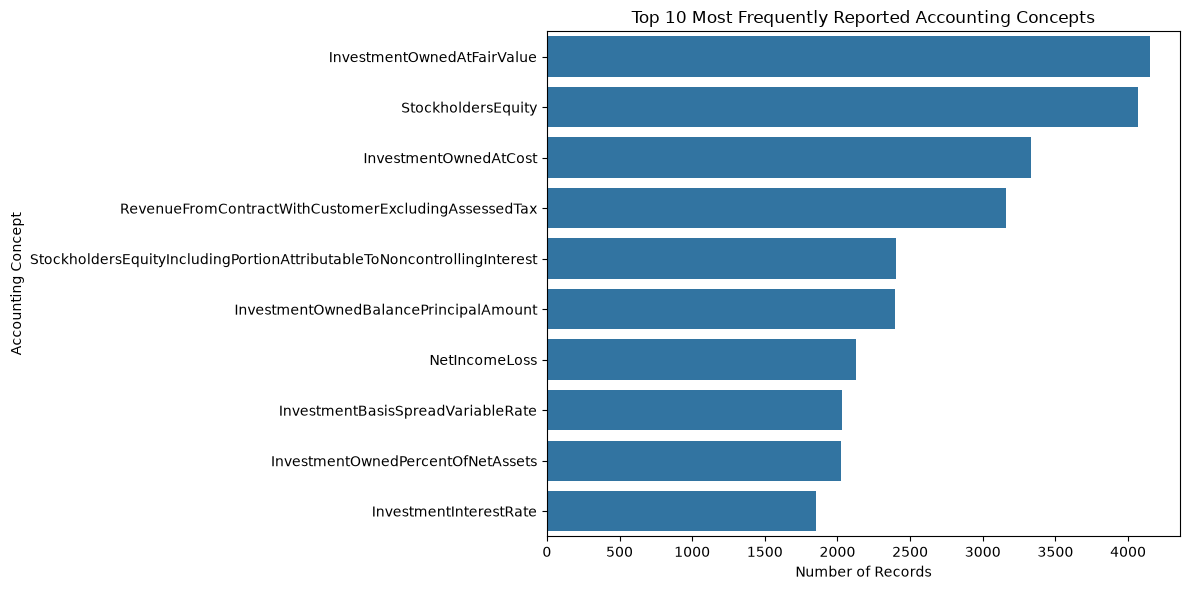

In [48]:
top_tags = df['tag'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_tags.values, y=top_tags.index)

plt.title('Top 10 Most Frequently Reported Accounting Concepts')
plt.xlabel('Number of Records')
plt.ylabel('Accounting Concept')

plt.tight_layout()
plt.show()

### Interpretation

- `InvestmentOwnedAtValue` is the most frequently reported accounting concept.
- `StockholdersEquity` and `InvestmentOwnedAtCost` are the second and third most frequent concepts.
- Investment-related concepts dominate the top 10.
- Revenue and net income concepts also appear frequently.

**Overall:** The dataset contains a strong focus on investment-related financial reporting. This may partly reflect the large representation of investment funds in our sample.

### Step 45: Companies with the Most Financial Records
#### Q4: Which companies have the highest number of financial records?

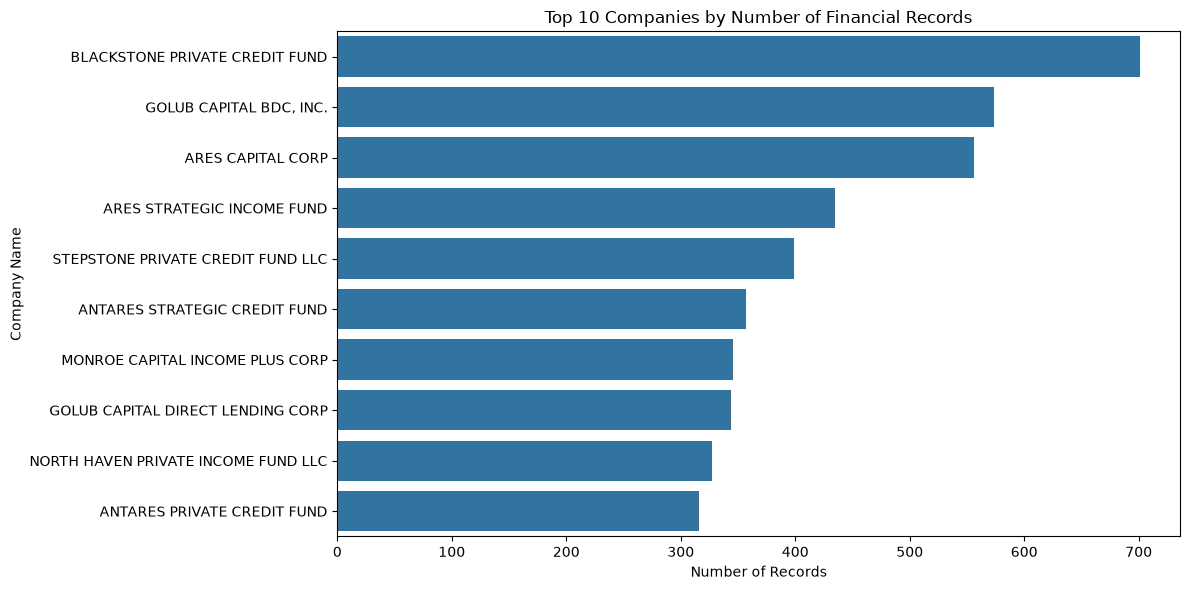

In [49]:
top_companies = df['name'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_companies.values, y=top_companies.index)

plt.title('Top 10 Companies by Number of Financial Records')
plt.xlabel('Number of Records')
plt.ylabel('Company Name')

plt.tight_layout()
plt.show()

### Interpretation

- BLACKSTONE PRIVATE CREDIT FUND contributes the highest number of financial records (approximately 700).
- GOLUB CAPITAL BDC, INC. and ARES CAPITAL CORP rank second and third.
- Most companies in the top 10 operate in private credit, investment, or lending.
- The number of records varies across companies.

**Overall:** Investment-related companies dominate the top 10. This is consistent with the high frequency of investment-related accounting concepts observed in the previous chart.

### Step 46: Distribution of Filing Types
#### Q5: How are records distributed between 10-K and 10-Q filings?

We'll compare the number of records reported under 10-K and 10-Q filings.

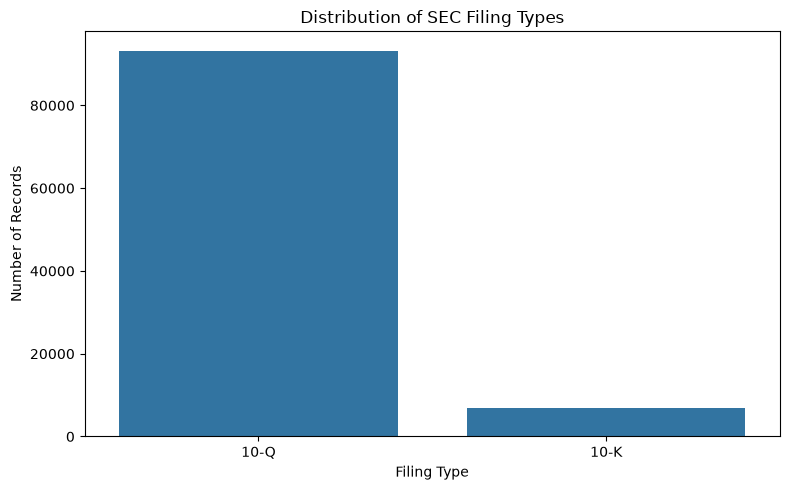

In [50]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='form')

plt.title('Distribution of SEC Filing Types')
plt.xlabel('Filing Type')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

### Interpretation

- 10-Q filings account for approximately 93% of the records.
- 10-K filings account for approximately 7%.
- 10-Q represents quarterly reports, which are generally unaudited.
- 10-K represents annual reports, which are audited and provide more comprehensive financial information.

**Overall:** The dataset is heavily dominated by quarterly filing records, with a much smaller proportion coming from annual filings.

### Step 47: Financial Records by Reporting Period

#### Q6: How do financial records vary across reporting periods?
This analysis examines the number of financial records reported in each reporting period to identify periods with higher or lower reporting activity.

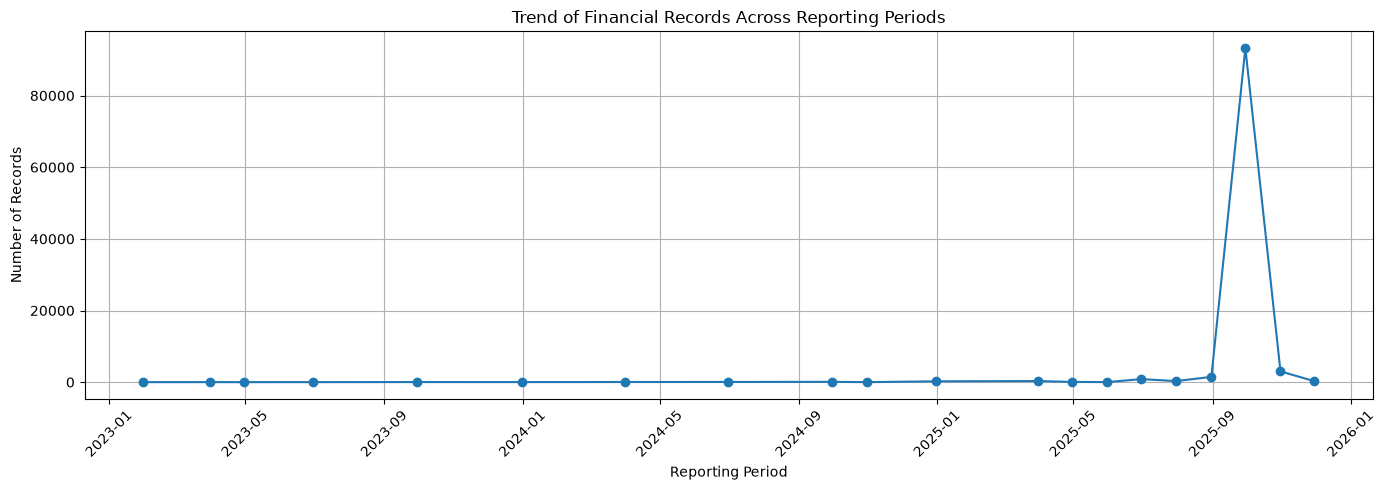

In [51]:
period_counts = df['period'].value_counts().sort_index()

plt.figure(figsize=(14, 5))
plt.plot(period_counts.index, period_counts.values, marker='o')

plt.title('Trend of Financial Records Across Reporting Periods')
plt.xlabel('Reporting Period')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation:
- September 30, 2025 contains approximately 93,000 records, creating a significant spike.
- Other reporting periods contain far fewer records.
- The chart does not show a consistent upward or downward trend.
- The sample is heavily concentrated in September 2025, making comparisons across periods difficult.

# Part 6: Bivariate Analysis
### Step 48: Compare Reported Quarters by Filing Type
#### Q7: How does the distribution of qtrs differ between 10-K and 10-Q filings?

This analysis compares the number of reported quarters (`qtrs`) across the two SEC filing types: 10-K and 10-Q. 

A box plot will help us compare their distributions, medians, spread, and potential outliers.

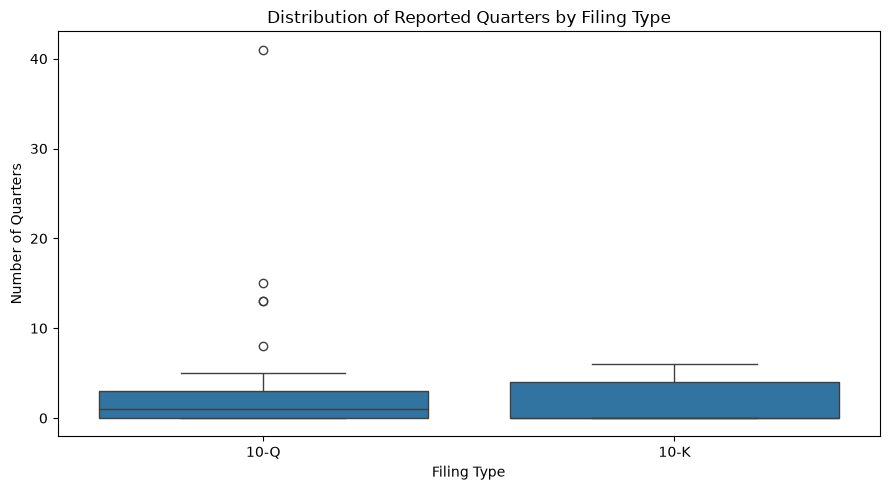

In [52]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='form', y='qtrs')

plt.title('Distribution of Reported Quarters by Filing Type')
plt.xlabel('Filing Type')
plt.ylabel('Number of Quarters')
plt.tight_layout()
plt.show()

### Interpretation:

- Both filing types have most of their `qtrs` values between 0 and 4.
- The median is approximately 1 for both filing types.
- The 10-K group has a slightly wider interquartile range than the 10-Q group.
- The 10-Q group contains four visible outliers, reaching as high as 41 quarters.
- No outlier points are visible for the 10-K group.

**Overall:** Both filing types have similar central distributions, but the 10-Q group contains several unusually high `qtrs` values.

### Step 49: Identify Missing Values by Accounting Concept
#### Q8: Which accounting concepts have the highest number of missing financial values?
This analysis examines missing financial values across accounting concepts (`tag`).

It identifies which accounting concepts have the highest number of records with missing financial values.

First, recreate the missing-value indicator because we reloaded the original dataset earlier:

In [53]:
df['value_missing'] = df['value'].isnull()

Now calculate missing values for each accounting concept:

In [54]:
missing_by_tag = df.groupby('tag')['value_missing'].sum()

missing_by_tag = missing_by_tag.sort_values(ascending=False).head(10)

display(missing_by_tag)

tag
NetIncomeLoss                                                                                              324
CommitmentsAndContingencies                                                                                200
StockholdersEquity                                                                                         124
AdjustmentsToAdditionalPaidInCapitalSharebasedCompensationRequisiteServicePeriodRecognitionValue           110
ProfitLoss                                                                                                 108
StockIssuedDuringPeriodValueNewIssues                                                                       84
AdjustmentsToAdditionalPaidInCapitalShareBasedCompensationStockOptionsRequisiteServicePeriodRecognition     63
PreferredStockValue                                                                                         56
StockIssuedDuringPeriodValueIssuedForServices                                                               

#### Step 50: Visualize Missing Values by Accounting Concept

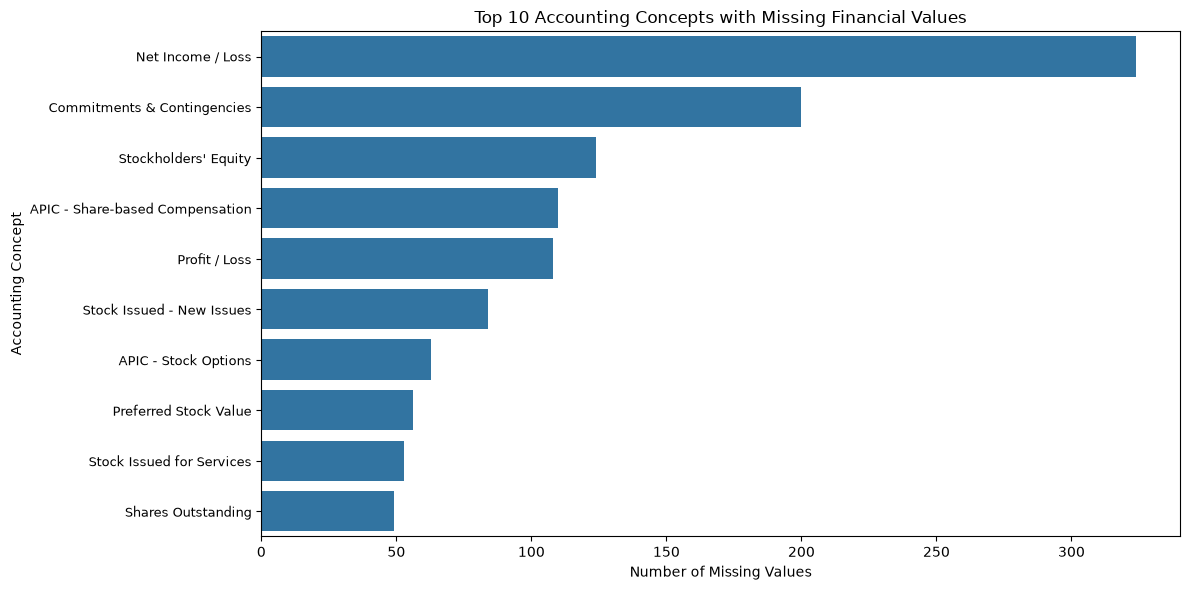

In [62]:
short_names = {
    'NetIncomeLoss': 'Net Income / Loss',
    'CommitmentsAndContingencies': 'Commitments & Contingencies',
    'StockholdersEquity': "Stockholders' Equity",
    'AdjustmentsToAdditionalPaidInCapitalSharebasedCompensationRequisiteServicePeriodRecognitionValue': 'APIC - Share-based Compensation',
    'ProfitLoss': 'Profit / Loss',
    'StockIssuedDuringPeriodValueNewIssues': 'Stock Issued - New Issues',
    'AdjustmentsToAdditionalPaidInCapitalShareBasedCompensationStockOptionsRequisiteServicePeriodRecognition': 'APIC - Stock Options',
    'PreferredStockValue': 'Preferred Stock Value',
    'StockIssuedDuringPeriodValueIssuedForServices': 'Stock Issued for Services',
    'SharesOutstanding': 'Shares Outstanding'
}

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=missing_by_tag.values,
    y=[short_names[tag] for tag in missing_by_tag.index]
)

ax.tick_params(axis='y', labelsize=9)

plt.title('Top 10 Accounting Concepts with Missing Financial Values')
plt.xlabel('Number of Missing Values')
plt.ylabel('Accounting Concept')

plt.tight_layout()
plt.show()

### Interpretation:
- Net Income / Loss has the highest number of missing financial values (324).
- Commitments & Contingencies ranks second with 200 missing values.
- Stockholders' Equity ranks third with 124 missing values.
- The remaining accounting concepts have fewer than 111 missing values each.
- Net Income / Loss has approximately 1.6 times as many missing values as Commitments & Contingencies.

**Overall:** Missing financial values are concentrated in certain accounting concepts, with Net Income / Loss having the highest count.

# Part 7: Answer Research Questions

In this section, we summarize the findings from our exploratory data analysis and answer the eight research questions using the results obtained in the previous sections.

## EDA Findings

---

### Q1. How are financial values distributed across the dataset?

- Financial values are **highly right-skewed**: most sit near zero, with a few extremely large positive or negative amounts.

- The variation comes from different accounting concepts and units of measurement.

- 📌 Values should not be compared directly without considering their context.

<br>

---

### Q2. How does the number of reported quarters (`qtrs`) vary across records?

- Most records have `qtrs` between **0 and 4**.

- Frequency drops as `qtrs` increases, with only a few records reaching **41 quarters**.

- 📌 Most reported financial facts cover relatively short durations.

<br>

---

### Q3. Which accounting concepts appear most frequently?

- Top 3: `InvestmentOwnedAtValue`, `StockholdersEquity`, `InvestmentOwnedAtCost`.

- Investment-related concepts dominate the top 10.

- 📌 This may partly reflect the large share of investment funds in the sample.

<br>

---

### Q4. Which companies have the most financial records?

- **BLACKSTONE PRIVATE CREDIT FUND** has the highest number of records, with about 700.

- It is followed by GOLUB CAPITAL BDC, INC. and ARES CAPITAL CORP.

- 📌 Most of the top 10 operate in private credit, investment, or lending.

<br>

---

### Q5. How are records split between 10-K and 10-Q filings?

- About **93%** are 10-Q and **7%** are 10-K.

- 📌 Quarterly filings clearly dominate the prepared dataset.

<br>

---

### Q6. How do records vary across reporting periods?

- **September 30, 2025** has about 93,000 records, far more than any other period.

- The dataset is heavily concentrated in this period, which makes period comparisons difficult.

- 📌 The spike reflects how the sample was built, not necessarily higher reporting activity.

<br>

---

### Q7. How does the `qtrs` distribution differ between 10-K and 10-Q filings?

- Both have similar central distributions, with most `qtrs` between 0 and 4.

- 10-K has a slightly wider interquartile range.

- 10-Q has several visible outlier points, reaching up to 41 quarters.

<br>

---

### Q8. Which accounting concepts have the most missing financial values?

| Concept | Missing values |
|---|---|
| `NetIncomeLoss` | 324 |
| `CommitmentsAndContingencies` | 200 |
| `StockholdersEquity` | 124 |

<br>

- `NetIncomeLoss` has about **1.6x** as many missing values as `CommitmentsAndContingencies`.

- 📌 Missing values are concentrated in certain accounting concepts.

# Part 8: Conclusion

This exploratory data analysis examined SEC financial statement records to understand their distributions, reporting patterns, and missing values.

<br>

---

### Key Findings

- Financial values are **highly right-skewed**, with substantial variation across accounting concepts and units.

- Investment-related concepts and investment companies dominate the most frequently reported records.

- The dataset contains significantly more **10-Q** records than **10-K** records.

- **September 2025** accounts for the majority of records, creating an imbalance in reporting-period coverage.

- Missing financial values are concentrated in certain accounting concepts, particularly `NetIncomeLoss`.

<br>

---

### Limitations

- The dataset is a sample of 100,000 records and may not represent the entire SEC database.

- Reporting periods are unevenly distributed, particularly September 2025.

- Financial values use different accounting concepts and units, which limits direct comparisons.

- Missing values and unusual observations may require further investigation.

<br>

---

### Final Conclusion

The analysis provides an overview of financial reporting patterns within the prepared SEC dataset. It highlights variations across companies, accounting concepts, filing types, and reporting periods. These findings help identify patterns and limitations that should be considered in further financial analysis.